# Implementation of K means clustering for mall customer segmentation

## importing necessary libraries

In [150]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
print("imported necessary libraries successfully")

imported necessary libraries successfully


## Exploratory Data Analysis

In [151]:
df = pd.read_csv('Mall_Customers.csv')
print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [152]:
print("count of missing values per column\n",df.isnull().sum())

count of missing values per column
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [153]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
None


In [154]:
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  0


In [155]:
print(df.drop(columns=['CustomerID']).describe())


              Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000          200.000000              200.000000
mean    38.850000           60.560000               50.200000
std     13.969007           26.264721               25.823522
min     18.000000           15.000000                1.000000
25%     28.750000           41.500000               34.750000
50%     36.000000           61.500000               50.000000
75%     49.000000           78.000000               73.000000
max     70.000000          137.000000               99.000000


In [156]:
df['Gender'] = df['Gender'].map({'Female':1, 'Male':0})
print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1       0   19                  15                      39
1           2       0   21                  15                      81
2           3       1   20                  16                       6
3           4       1   23                  16                      77
4           5       1   31                  17                      40


In [157]:
counts = df['Gender'].value_counts()
ratios = df['Gender'].value_counts(normalize=True)

distribution_df = pd.DataFrame({
    'Count':counts,
    'Ratio':ratios
})
distribution_df.index = distribution_df.index.map({1:'Female', 0:'Male'})
print(distribution_df)

        Count  Ratio
Gender              
Female    112   0.56
Male       88   0.44


/tmp/ipykernel_7492/2835043810.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_7492/2835043810.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['Male (0)', 'Female (1)'])
/tmp/ipykernel_7492/2835043810.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_7492/2835043810.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(['Male (0)', 'Female (1)'])


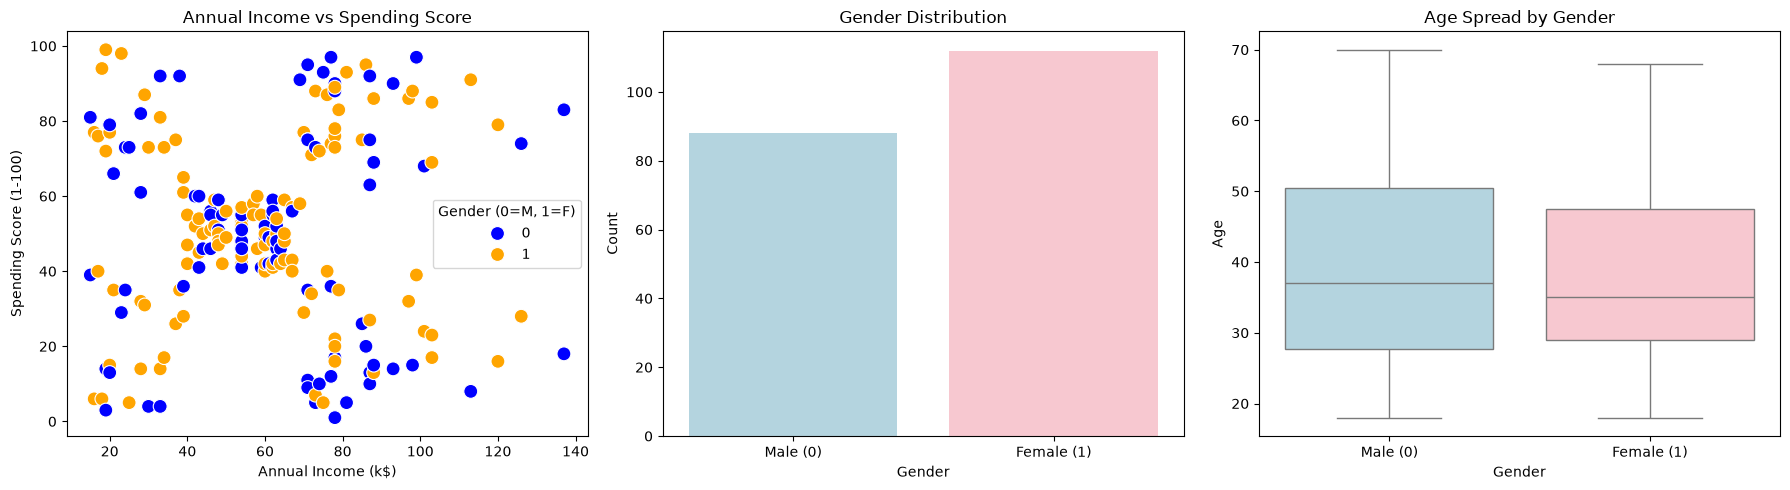

In [158]:
fig, axes = plt.subplots(1,3,figsize=(18,5))
sns.scatterplot(
    ax=axes[0],
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    data=df,
    palette=['blue', 'orange'],
    s=100
)
axes[0].set_title('Annual Income vs Spending Score')
axes[0].legend(title='Gender (0=M, 1=F)')

sns.countplot(
    ax=axes[1],
    x='Gender',
    data=df,
    palette=['lightblue', 'pink']
)
axes[1].set_title('Gender Distribution')
axes[1].set_xticklabels(['Male (0)', 'Female (1)'])
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Count')

sns.boxplot(
    ax=axes[2],
    x='Gender',
    y='Age',
    data=df,
    palette=['lightblue', 'pink']
)
axes[2].set_title('Age Spread by Gender')
axes[2].set_xticklabels(['Male (0)', 'Female (1)'])
axes[2].set_xlabel('Gender')

plt.tight_layout()
plt.show()

## General K-Means clustering function

In [159]:
def kmeans(X, k, max_iters = 1000, tol=1e-4, random_state = 42):
    """
    Applies K-Means clustering

    Parameters:
    - X: numpy array of shape (n_samples, n_features)
    - k: number of clusters
    - max_iters: maximum number of iterations
    - tol: tolerance to check for convergence
    - random_state: seed for reproducibility

    Returns:
    - centroids: final cluster centers
    - labels: cluster assignment for each data point
    """

    np.random.seed(random_state)
    random_indices = np.random.choice(X.shape[0], k, replace=False)
    centroids = X[random_indices]

    for iteration in range(max_iters):
        distances = np.sqrt(((X[:, np.newaxis,:] - centroids[np.newaxis, :, :])**2).sum(axis=2))
        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([
            X[labels == i].mean(axis=0) if np.any(labels == i) else centroids[i]
            for i in range(k)
        ])

        if np.all(np.abs(new_centroids - centroids) < tol):
            break

        centroids = new_centroids
    return centroids, labels

### Feature scaling

In [160]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X_raw = df[features].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

### Inertia and elbow curve
Inertia (Sum of squared errors / SSE) measures how tightly grouped the points are around their cluster centroids. Lower inertia means tigther, more cohesive clusters.

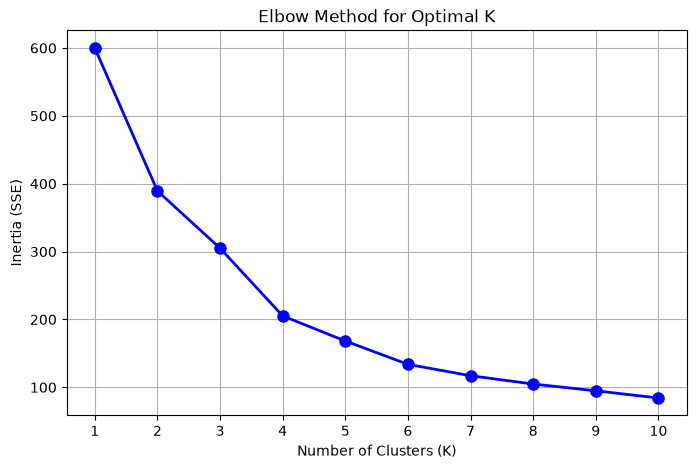

In [161]:
inertias = []
K_values = range(1,11)

for k in K_values:
    centroids, labels = kmeans(X_scaled, k)

    distances = np.sqrt(((X_scaled[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2).sum(axis=2))
    min_distances = distances[np.arange(len(labels)), labels]

    inertia = (min_distances ** 2).sum()
    inertias.append(inertia)

plt.figure(figsize=(8,5))
plt.plot(K_values, inertias, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (SSE)')
plt.xticks(K_values)
plt.grid(True)
plt.show()

### Determining optimal K 

In [162]:
k_arr = np.array(list(K_values))
inertia_arr = np.array(inertias)

p1 = np.array([k_arr[0], inertia_arr[0]])
p2 = np.array([k_arr[-1], inertia_arr[-1]])

numerator = np.abs((p2[1] - p1[1]) * k_arr - (p2[0] - p1[0]) * inertia_arr + p2[0] * p1[1] - p2[1] * p1[0])
denominator = np.sqrt((p2[1] - p1[1])**2 + (p2[0] - p1[0])**2)
distances = numerator / denominator

optimal_idx = np.argmax(distances)
optimal_k = k_arr[optimal_idx]
print(f"Mathematically optimal K based on the elbow method:{optimal_k}")

Mathematically optimal K based on the elbow method:4


### Training k means clustering model
 

--- Cluster Centers (Original Scale) ---
               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        32.875000           86.100000               81.525000
1        25.438596           40.000000               60.298246
2        53.984615           47.707692               39.969231
3        39.368421           86.500000               19.578947




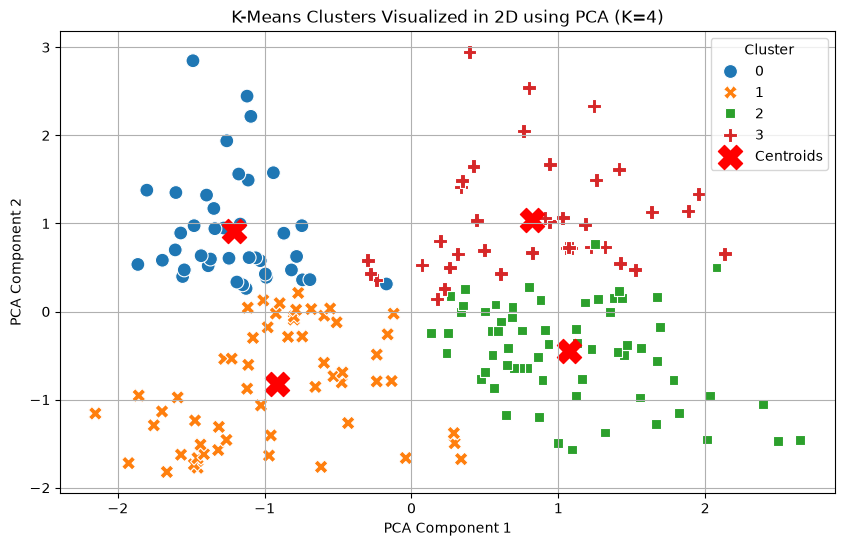

--- Cluster Profiles (Averages) ---
               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        32.875000           86.100000               81.525000
1        25.438596           40.000000               60.298246
2        53.984615           47.707692               39.969231
3        39.368421           86.500000               19.578947


In [163]:
centroids_scaled, labels = kmeans(X_scaled, k=optimal_k, random_state=42)
df['Cluster'] = labels
centroids_original = scaler.inverse_transform(centroids_scaled)

feature_names = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
centroids_df = pd.DataFrame(centroids_original, columns=feature_names)
centroids_df.index.name = 'Cluster'
print("--- Cluster Centers (Original Scale) ---")
print(centroids_df)
print("\n") 

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(centroids_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0], 
    y=X_pca[:, 1], 
    hue=df['Cluster'], 
    palette='tab10', 
    s=100, 
    style=df['Cluster'],
    legend='full'
)
plt.scatter(
    centroids_pca[:, 0], 
    centroids_pca[:, 1], 
    s=300, 
    c='red', 
    marker='X', 
    label='Centroids'
)
plt.title(f'K-Means Clusters Visualized in 2D using PCA (K={optimal_k})')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

profile_summary = df.groupby('Cluster')[feature_names].mean()
print("--- Cluster Profiles (Averages) ---")
print(profile_summary)